# Step 3 — 모델 다변화 (Model Diversification: CatBoost & XGBoost)

- **목적 (Objective)**: 성능 개선이 아니라 **앙상블 다양성(Model Diversity) 확보**.
  LightGBM과 **상관이 낮은 오차 구조**를 갖는 베이스 모델을 추가해 Step 4 스태킹의 재료를 만든다.
- **단일 변경점 (§3-4)**: 피처 구성은 Step 1 채택본(BASE 21 + 빈도 인코딩 2)으로 **고정**. 변경점은 학습 알고리즘뿐이다.

### 알고리즘 선택 근거 (Rationale)

| 모델 | LightGBM과의 차이 | 기대 효과 |
|---|---|---|
| **CatBoost** | **Ordered Target Statistics** 로 범주형을 처리하고 **Oblivious Tree**(모든 분기가 같은 조건) 사용 | 분할 구조가 근본적으로 달라 오차 상관이 가장 낮을 것으로 기대 |
| **XGBoost** | Level-wise 성장 (LightGBM은 Leaf-wise) | 트리 형태 차이에 따른 중간 수준 다양성 |

### 채택 기준 (§4 Step 3) — 성능이 아닌 **다양성** 기준

1. 단독 OOF AUC **≥ 0.95** (너무 약하면 스태커에 잡음만 추가)
2. `lgbm_tuned` 와의 **Spearman 상관 < 0.99**
   → AUC는 순위 기반 지표이므로 Pearson이 아닌 **Spearman**으로 판정한다.
     (기존 모델 실측: Pearson 0.9947인 `mlp` 도 Spearman은 0.936으로 충분한 다양성 보유)

### 사전 비용 측정 (1-Fold Probe)

Step 1·2에서 런타임 추정을 2회 연속 실패했으므로(§7), 본 단계는 **fold 0만 먼저 측정**한 뒤 진행했다.

| 모델 | fold 0 AUC | iterations | fold 0 시간 | 5-fold 추정 |
|---|---|---|---|---|
| CatBoost | 0.95954 | 3,620 | 234s | **~20분** |
| XGBoost | 0.95938 | 921 | 23s | **~2분** |

---

## 1. 환경 설정 및 Step 1 구성 복원

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from catboost import CatBoostClassifier
from scipy.stats import rankdata
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
SEED = 42
START_TIME = time.time()
COLOR_MAIN, COLOR_ALT, COLOR_MUTED = "#2a78d6", "#eb6834", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold",
})
import catboost
print("catboost", catboost.__version__, "| xgboost", xgb.__version__)

catboost 1.2.10 | xgboost 3.4.1


In [2]:
REQUIRED_FILES = ["train.csv", "test.csv", "sample_submission.csv"]
has_all = lambda f: all((f / n).is_file() for n in REQUIRED_FILES)
kaggle = Path("/kaggle/input")
cands = (sorted({p.parent for p in kaggle.glob("**/train.csv") if has_all(p.parent)}) if kaggle.exists()
         else list(dict.fromkeys(p.resolve() for p in (Path("data"), Path("../data")) if has_all(p))))
DATA_DIR = cands[0]
OUT_DIR = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
TARGET = "satisfaction"
CAT_COLS = ["Gender", "Customer Type", "Type of Travel", "Class"]
y = train[TARGET].astype(int)

X = train.drop(columns=["id", TARGET]).copy()
X_test = test.drop(columns=["id"]).copy()

FREQ_COLS = ["Age", "Flight Distance"]


def add_freq_features(fit_df, *apply_dfs):
    counts = {c: fit_df[c].value_counts() for c in FREQ_COLS}
    out = []
    for df in (fit_df, *apply_dfs):
        df = df.copy()
        for c in FREQ_COLS:
            df[f"{c}_freq"] = df[c].map(counts[c]).fillna(0).astype(float)
        out.append(df)
    return out


N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(train, y))
fold_id = np.full(len(train), -1)
for k, (_, va_idx) in enumerate(FOLDS):
    fold_id[va_idx] = k

_ref = pd.read_csv(OUT_DIR / "oof_lgbm_tuned.csv", usecols=["id", "fold"])
_chk = pd.DataFrame({"id": train["id"].values, "fold": fold_id}).merge(
    _ref, on="id", suffixes=("_new", "_ref"), validate="one_to_one")
assert len(_chk) == len(train) and (_chk["fold_new"] == _chk["fold_ref"]).all(), "Fold 계약 불일치"
print("fold 계약 검증 PASS")


def save_predictions(name, oof, test_pred):
    assert np.isfinite(oof).all() and np.isfinite(test_pred).all()
    pd.DataFrame({"id": train["id"].values, "fold": fold_id, "pred": oof}).to_csv(OUT_DIR / f"oof_{name}.csv", index=False)
    pd.DataFrame({"id": test["id"].values, "pred": test_pred}).to_csv(OUT_DIR / f"test_{name}.csv", index=False)
    print(f"saved oof_{name}.csv / test_{name}.csv")

fold 계약 검증 PASS


## 2. CatBoost 5-Fold

- **범주형 처리**: `cat_features` 에 4개 열을 지정해 **Ordered Target Statistics** 를 사용한다.
  LightGBM의 분할 기반 범주 처리와 원리가 달라 다양성의 주요 원천이 된다.
- **결측 처리**: CatBoost는 `Arrival Delay in Minutes` 의 NaN을 내부적으로 처리하므로 대체하지 않는다.
- 하이퍼파라미터는 **튜닝하지 않는다** — 본 단계의 목적은 성능이 아닌 다양성 확보이며,
  LightGBM과 동일하게 `learning_rate=0.05`, `early_stopping=100` 만 맞춘다.

In [3]:
def run_catboost():
    oof = np.full(len(X), np.nan)
    test_pred = np.zeros(len(X_test))
    aucs, iters = [], []
    for k, (tr_idx, va_idx) in enumerate(FOLDS):
        X_tr, X_va, X_te = add_freq_features(X.iloc[tr_idx], X.iloc[va_idx], X_test)
        model = CatBoostClassifier(
            iterations=5000, learning_rate=0.05, eval_metric="AUC",
            random_seed=SEED, early_stopping_rounds=100, verbose=0,
            cat_features=CAT_COLS, thread_count=-1,
        )
        model.fit(X_tr, y.iloc[tr_idx], eval_set=(X_va, y.iloc[va_idx]))
        oof[va_idx] = model.predict_proba(X_va)[:, 1]
        test_pred += model.predict_proba(X_te)[:, 1] / N_FOLDS
        aucs.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        iters.append(model.get_best_iteration())
        print(f"  fold {k + 1}: AUC {aucs[-1]:.5f}  iters {iters[-1]}  ({time.time() - START_TIME:.0f}s)", flush=True)
    return oof, test_pred, np.array(aucs), iters


print("CatBoost 5-fold 학습")
cat_oof, cat_test, cat_folds, cat_iters = run_catboost()
cat_auc = roc_auc_score(y, cat_oof)
print(f"\nCatBoost OOF AUC = {cat_auc:.5f}  (fold std {cat_folds.std():.5f})")
save_predictions("cat", cat_oof, cat_test)

CatBoost 5-fold 학습


  fold 1: AUC 0.95954  iters 3620  (270s)


  fold 2: AUC 0.95825  iters 4672  (662s)


  fold 3: AUC 0.96012  iters 2499  (893s)


  fold 4: AUC 0.95933  iters 2470  (1125s)


  fold 5: AUC 0.95954  iters 2723  (1397s)



CatBoost OOF AUC = 0.95935  (fold std 0.00061)


saved oof_cat.csv / test_cat.csv


## 3. XGBoost 5-Fold

- **범주형 처리**: `enable_categorical=True` + pandas `category` dtype. 내부적으로 분할 기반 처리를 수행한다.
- **트리 성장 방식**: Level-wise (LightGBM은 Leaf-wise) — 구조적 차이가 다양성의 원천.
- 동일하게 `learning_rate=0.05`, `early_stopping_rounds=100` 으로 맞춘다.

In [4]:
def run_xgboost():
    oof = np.full(len(X), np.nan)
    test_pred = np.zeros(len(X_test))
    aucs, iters = [], []
    cats = {c: sorted(train[c].unique()) for c in CAT_COLS}
    for k, (tr_idx, va_idx) in enumerate(FOLDS):
        frames = add_freq_features(X.iloc[tr_idx], X.iloc[va_idx], X_test)
        for df in frames:
            for c in CAT_COLS:
                df[c] = pd.Categorical(df[c], categories=cats[c])
        X_tr, X_va, X_te = frames
        model = xgb.XGBClassifier(
            n_estimators=5000, learning_rate=0.05, eval_metric="auc",
            enable_categorical=True, tree_method="hist",
            early_stopping_rounds=100, random_state=SEED, n_jobs=-1,
        )
        model.fit(X_tr, y.iloc[tr_idx], eval_set=[(X_va, y.iloc[va_idx])], verbose=False)
        oof[va_idx] = model.predict_proba(X_va)[:, 1]
        test_pred += model.predict_proba(X_te)[:, 1] / N_FOLDS
        aucs.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        iters.append(model.best_iteration)
        print(f"  fold {k + 1}: AUC {aucs[-1]:.5f}  iters {iters[-1]}  ({time.time() - START_TIME:.0f}s)", flush=True)
    return oof, test_pred, np.array(aucs), iters


print("XGBoost 5-fold 학습")
xgb_oof, xgb_test, xgb_folds, xgb_iters = run_xgboost()
xgb_auc = roc_auc_score(y, xgb_oof)
print(f"\nXGBoost OOF AUC = {xgb_auc:.5f}  (fold std {xgb_folds.std():.5f})")
save_predictions("xgb", xgb_oof, xgb_test)

XGBoost 5-fold 학습


  fold 1: AUC 0.95938  iters 921  (1431s)


  fold 2: AUC 0.95823  iters 1445  (1481s)


  fold 3: AUC 0.96011  iters 1101  (1519s)


  fold 4: AUC 0.95940  iters 963  (1553s)


  fold 5: AUC 0.95938  iters 917  (1584s)



XGBoost OOF AUC = 0.95929  (fold std 0.00060)


saved oof_xgb.csv / test_xgb.csv


## 4. 다양성 분석 (Diversity Analysis) ★ 본 단계의 판정 근거

- **Spearman(순위) 상관**으로 판정한다. ROC-AUC는 예측값의 **순위**만 사용하므로,
  Pearson 상관이 높아도 순위 구조가 다르면 앙상블에 기여한다.
- 판정: 단독 OOF ≥ 0.95 **且** `lgbm_tuned` 와 Spearman < 0.99

In [5]:
models = {}
for name in ["lgbm_tuned", "lgbm_fe", "mlp", "cat", "xgb"]:
    d = pd.read_csv(OUT_DIR / f"oof_{name}.csv").sort_values("id")
    models[name] = d["pred"].values
names = list(models)
ranks = {n: rankdata(models[n]) for n in names}

spear = pd.DataFrame(
    [[np.corrcoef(ranks[a], ranks[b])[0, 1] for b in names] for a in names],
    index=names, columns=names)
pears = pd.DataFrame(
    [[np.corrcoef(models[a], models[b])[0, 1] for b in names] for a in names],
    index=names, columns=names)

print("--- Spearman (순위) 상관 ---")
print(spear.round(4).to_string())
print("\n--- Pearson 상관 (참고) ---")
print(pears.round(4).to_string())

gate = pd.DataFrame([{
    "모델": n,
    "단독 OOF": round(roc_auc_score(y, models[n]), 5),
    "Spearman vs lgbm_tuned": round(spear.loc[n, "lgbm_tuned"], 4),
    "OOF≥0.95": "✅" if roc_auc_score(y, models[n]) >= 0.95 else "❌",
    "상관<0.99": "✅" if spear.loc[n, "lgbm_tuned"] < 0.99 else "❌",
} for n in ["cat", "xgb", "mlp"]])
print("\n--- 스태킹 입력 채택 판정 ---")
print(gate.to_string(index=False))

--- Spearman (순위) 상관 ---
            lgbm_tuned  lgbm_fe     mlp     cat     xgb
lgbm_tuned      1.0000   0.9836  0.9357  0.9802  0.9811
lgbm_fe         0.9836   1.0000  0.9324  0.9676  0.9700
mlp             0.9357   0.9324  1.0000  0.9374  0.9267
cat             0.9802   0.9676  0.9374  1.0000  0.9785
xgb             0.9811   0.9700  0.9267  0.9785  1.0000

--- Pearson 상관 (참고) ---
            lgbm_tuned  lgbm_fe     mlp     cat     xgb
lgbm_tuned      1.0000   0.9990  0.9947  0.9982  0.9983
lgbm_fe         0.9990   1.0000  0.9941  0.9970  0.9975
mlp             0.9947   0.9941  1.0000  0.9944  0.9933
cat             0.9982   0.9970  0.9944  1.0000  0.9982
xgb             0.9983   0.9975  0.9933  0.9982  1.0000



--- 스태킹 입력 채택 판정 ---
 모델  단독 OOF  Spearman vs lgbm_tuned OOF≥0.95 상관<0.99
cat 0.95935                  0.9802        ✅       ✅
xgb 0.95929                  0.9811        ✅       ✅
mlp 0.95730                  0.9357        ✅       ✅


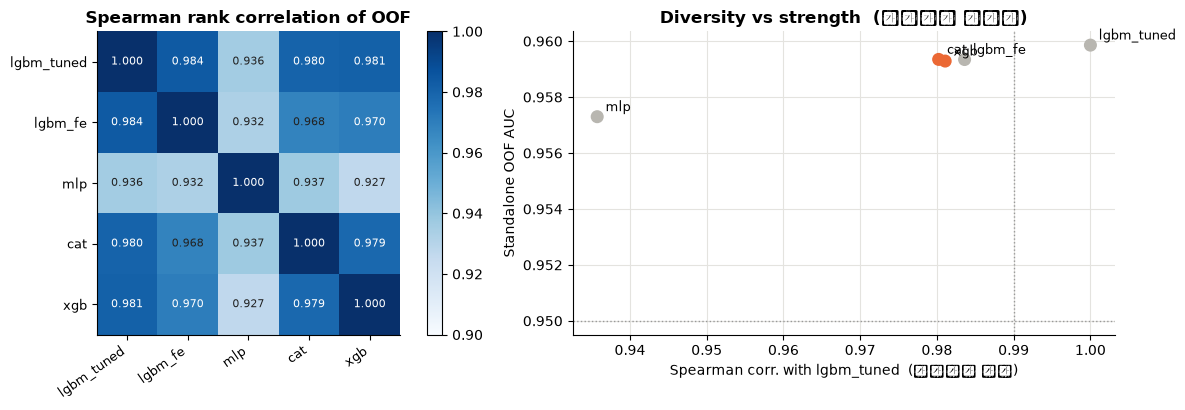

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

im = axes[0].imshow(spear.values, cmap="Blues", vmin=0.9, vmax=1.0)
axes[0].set_xticks(range(len(names)), names, rotation=35, ha="right", fontsize=9)
axes[0].set_yticks(range(len(names)), names, fontsize=9)
for i in range(len(names)):
    for j in range(len(names)):
        v = spear.values[i, j]
        axes[0].text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                     color="white" if v > 0.97 else "#222")
axes[0].set_title("Spearman rank correlation of OOF")
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046)

solo = [roc_auc_score(y, models[n]) for n in names]
corr = [spear.loc[n, "lgbm_tuned"] for n in names]
axes[1].scatter(corr, solo, s=70, color=[COLOR_ALT if n in ("cat", "xgb") else COLOR_MUTED for n in names],
                zorder=3)
for n, c, s in zip(names, corr, solo):
    axes[1].annotate(n, (c, s), textcoords="offset points", xytext=(6, 4), fontsize=9)
axes[1].axhline(0.95, color="#999", linestyle=":", linewidth=1)
axes[1].axvline(0.99, color="#999", linestyle=":", linewidth=1)
axes[1].set_xlabel("Spearman corr. with lgbm_tuned  (낮을수록 다양)")
axes[1].set_ylabel("Standalone OOF AUC")
axes[1].set_title("Diversity vs strength  (좌상단이 이상적)")
plt.tight_layout(); plt.show()

## 5. 단순 블렌딩 사전 확인 (Naive Blend Probe)

Step 4의 **비교 하한선**을 미리 잡아둔다. 동일 가중 rank-average가 `lgbm_tuned` 단독을 넘지 못하면,
**학습된 스태커가 필요**하다는 근거가 된다 (§4 Step 4).

In [7]:
from itertools import combinations

probe = []
base = roc_auc_score(y, models["lgbm_tuned"])
for r in range(2, len(names) + 1):
    for combo in combinations(names, r):
        if "lgbm_tuned" not in combo:
            continue
        avg = np.mean([rankdata(models[n]) for n in combo], axis=0)
        probe.append({"조합": " + ".join(combo), "n": r, "rank-avg OOF": roc_auc_score(y, avg)})

probe_df = pd.DataFrame(probe).sort_values("rank-avg OOF", ascending=False)
probe_df["Δ vs lgbm_tuned"] = (probe_df["rank-avg OOF"] - base).round(5)
probe_df["rank-avg OOF"] = probe_df["rank-avg OOF"].round(5)
print(f"lgbm_tuned 단독 = {base:.5f}\n")
print(probe_df.head(10).to_string(index=False))
print(f"\n단순 평균이 단독을 넘는 조합: {(probe_df['Δ vs lgbm_tuned'] > 0).sum()} / {len(probe_df)}")

probe_df.to_csv(OUT_DIR / "step3_blend_probe.csv", index=False)
pd.DataFrame({"model": ["cat", "xgb"], "oof": [cat_auc, xgb_auc],
              "folds": [cat_folds.tolist(), xgb_folds.tolist()],
              "iters": [cat_iters, xgb_iters]}).to_csv(OUT_DIR / "step3_summary.csv", index=False)
print(f"\n전체 실행 시간: {time.time() - START_TIME:.0f}초")

lgbm_tuned 단독 = 0.95986

                                    조합  n  rank-avg OOF  Δ vs lgbm_tuned
            lgbm_tuned + lgbm_fe + cat  3       0.95989          0.00003
      lgbm_tuned + lgbm_fe + cat + xgb  4       0.95988          0.00003
lgbm_tuned + lgbm_fe + mlp + cat + xgb  5       0.95986          0.00000
                      lgbm_tuned + cat  2       0.95984         -0.00001
            lgbm_tuned + lgbm_fe + xgb  3       0.95984         -0.00001
                lgbm_tuned + cat + xgb  3       0.95982         -0.00003
      lgbm_tuned + lgbm_fe + mlp + xgb  4       0.95981         -0.00005
                      lgbm_tuned + xgb  2       0.95980         -0.00005
      lgbm_tuned + lgbm_fe + mlp + cat  4       0.95980         -0.00006
                  lgbm_tuned + lgbm_fe  2       0.95978         -0.00008

단순 평균이 단독을 넘는 조합: 2 / 15

전체 실행 시간: 1591초
